# 02 · Zerlegung, Bewerter und Reaktionsregeln

**Hier entsteht der methodische Beitrag.** Pro Modell lernen wir drei kleine, lesbare Entscheidungsbäume:

| Baum | Lernziel | Rolle |
|---|---|---|
| `distribution` | menschliche Stimmenverteilung | **aleatorisch**: Ist der Fall *debatable*? |
| `epistemic` | Mehrheitsabweichung, **nur auf klaren Fällen** trainiert | **epistemisch**: Ist das Modell *uncertain*? |
| `risk` | Mehrheitsabweichung auf allen Fällen | Vergleich: vermischt beide Ursachen |

"Klar" heisst: menschliche Entropie im unteren Drittel der **Trainingsdaten** (Schwelle in der Config, vor dem Test festgelegt).
Eine Mehrheitsabweichung auf diesen Fällen dient als **operationaler Stellvertreter** für einen Modellfehler.
Sie beweist nicht, dass die Antwort objektiv falsch ist: Auch bei hoher Übereinstimmung kann eine Minderheitslesart vertretbar sein.

**Kerntest (Dissoziation):** Helfen diese Signale, menschliche Uneinigkeit und Mehrheitsabweichungen auf Fällen mit hoher
menschlicher Übereinstimmung auseinanderzuhalten? Prompt-Variation ist dabei ein messbarer Stellvertreter für epistemische
Unsicherheit, kein Nachweis. Die Verbindung zum Credal-CBM-Paper ist eine davon inspirierte Vereinfachung.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "config/project.json").exists())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Image
from uncertainty_project.common import config
CFG = config(ROOT)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
print("Projekt:", ROOT.name, "| Modelle:", list(CFG["models"]))

Projekt: uncertainty_project | Modelle: ['gpt', 'claude']


In [2]:
from uncertainty_project.data import load_split
from uncertainty_project.api import pending_requests, model_keys
from uncertainty_project.experiment import train_development, freeze_experiment, experiment_directory

train, dev = load_split(ROOT, "train"), load_split(ROOT, "dev")
missing = {k: len(pending_requests(ROOT, train, k)) + len(pending_requests(ROOT, dev, k)) for k in model_keys(ROOT)}
READY = all(v == 0 for v in missing.values())
print("Fehlende Train-/Dev-Antworten:", missing)
if not READY:
    print("Zuerst Notebook 01 mit STAGE = 'train_dev' für alle Modelle abschliessen.")

Fehlende Train-/Dev-Antworten: {'gpt': 0, 'claude': 0}


In [3]:
if READY:
    bundles, report = train_development(ROOT)
    OUT = experiment_directory(ROOT) / "development"
    print("Ergebnisse gespeichert in:", OUT.relative_to(ROOT))
    print("Menschliche Schwellen (aus Train):", report["meta"]["human_thresholds"])

Ergebnisse gespeichert in: outputs\experiments\chaos_mnli_v2_two_models_0ed06cd43089\development
Menschliche Schwellen (aus Train): {'clear_max_entropy': 0.6243943715625421, 'debatable_min_entropy': 0.6828639224630875, 'clarify_cue_threshold': 0.5}


## 1 · Dissoziation: Welches Signal misst was?

- `auroc_debatable`: Erkennt das Signal Fälle, bei denen **Menschen uneinig** sind? (0.5 = Zufall)
- `auroc_error_on_clear_cases`: Erkennt es **Mehrheitsabweichungen auf klaren Fällen**?
- `*_ci_low/high`: 95%-Intervalle (Bootstrap über Ausgangssätze). Bei wenigen Abweichungen auf klaren Fällen sind sie breit.
- Gewünscht: aleatorische Signale hoch in Spalte 1, ~0.5 in Spalte 2; epistemische umgekehrt.
- `joint_*`: 10 Köpfe (GPT + Claude zusammen). Diese Variante braucht beide Anbieter.
- `specialisation`: die vorab festgelegten Hauptvergleiche (siehe `analysis_plan` in `config/project.json`). Differenz > 0 mit Intervall über 0 = belastbarer Vorteil.
- `learned_entropy_direct`: Baum, der die menschliche Entropie direkt vorhersagt (Robustheitscheck). `baseline_label_confidence`: Risiko nur aus Antwortlabel + Konfidenz.


=== gpt


,signal,intended_component,auroc_debatable,auroc_error_on_clear_cases,spearman_human_entropy,auroc_error_all_cases,n,n_clear,errors_on_clear,auroc_debatable_ci_low,auroc_debatable_ci_high,auroc_error_on_clear_ci_low,auroc_error_on_clear_ci_high
0,model_total_entropy,mixed,0.553,0.683,0.087,0.616,322,123,36,0.498,0.614,0.562,0.786
1,model_expected_entropy,aleatoric,0.549,0.697,0.095,0.625,322,123,36,0.496,0.613,0.577,0.800
2,model_epistemic_mi,epistemic,0.543,0.673,0.040,0.574,322,123,36,0.482,0.603,0.565,0.769
3,model_credal_width,epistemic,0.553,0.702,0.067,0.608,322,123,36,0.492,0.615,0.600,0.793
4,model_label_flips,epistemic,0.501,0.549,-0.053,0.500,322,123,36,0.467,0.537,0.473,0.627
5,model_one_minus_confidence,mixed,0.538,0.675,0.055,0.613,322,123,36,0.484,0.599,0.552,0.781
6,learned_human_entropy,aleatoric,0.706,0.628,0.401,0.544,322,123,36,0.651,0.758,0.534,0.735
7,learned_epistemic_risk,epistemic,0.573,0.948,0.223,0.806,322,123,36,0.505,0.635,0.914,0.980
8,learned_risk_all_cases,mixed,0.600,0.934,0.249,0.792,322,123,36,0.535,0.664,0.889,0.968
9,baseline_answer_label,baseline,0.556,0.862,0.232,0.711,322,123,36,0.503,0.609,0.809,0.907


Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):


,rank,target,signal,minus,auroc_difference,ci_95_low,ci_95_high,valid_resamples,question
0,primary,debatable,learned_human_entropy,learned_epistemic_risk,0.133,0.056,0.209,500,Does the disagreement signal detect debatable ...
1,primary,error_on_clear,learned_epistemic_risk,learned_human_entropy,0.320,0.201,0.418,500,Does the risk signal detect majority deviation...
2,primary,error_on_clear,learned_epistemic_risk,baseline_label_confidence,-0.002,-0.024,0.017,500,"Do ensemble signals (MI, credal width, cues) a..."
3,secondary,debatable,learned_entropy_direct,learned_human_entropy,0.005,-0.034,0.044,500,Robustness: does predicting human entropy dire...



=== claude


,signal,intended_component,auroc_debatable,auroc_error_on_clear_cases,spearman_human_entropy,auroc_error_all_cases,n,n_clear,errors_on_clear,auroc_debatable_ci_low,auroc_debatable_ci_high,auroc_error_on_clear_ci_low,auroc_error_on_clear_ci_high
0,model_total_entropy,mixed,0.571,0.803,0.183,0.741,322,123,37,0.506,0.628,0.700,0.887
1,model_expected_entropy,aleatoric,0.568,0.791,0.168,0.728,322,123,37,0.503,0.624,0.677,0.880
2,model_epistemic_mi,epistemic,0.586,0.685,0.219,0.668,322,123,37,0.528,0.647,0.576,0.785
3,model_credal_width,epistemic,0.582,0.713,0.223,0.680,322,123,37,0.523,0.643,0.602,0.806
4,model_label_flips,epistemic,0.537,0.618,0.187,0.647,322,123,37,0.492,0.581,0.539,0.692
5,model_one_minus_confidence,mixed,0.562,0.795,0.183,0.758,322,123,37,0.496,0.619,0.696,0.882
6,learned_human_entropy,aleatoric,0.678,0.799,0.368,0.632,322,123,37,0.613,0.727,0.726,0.869
7,learned_epistemic_risk,epistemic,0.518,0.869,0.123,0.762,322,123,37,0.458,0.577,0.795,0.937
8,learned_risk_all_cases,mixed,0.604,0.906,0.287,0.781,322,123,37,0.546,0.658,0.854,0.947
9,baseline_answer_label,baseline,0.552,0.853,0.174,0.679,322,123,37,0.498,0.611,0.785,0.906


Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):


,rank,target,signal,minus,auroc_difference,ci_95_low,ci_95_high,valid_resamples,question
0,primary,debatable,learned_human_entropy,learned_epistemic_risk,0.160,0.073,0.236,500,Does the disagreement signal detect debatable ...
1,primary,error_on_clear,learned_epistemic_risk,learned_human_entropy,0.069,-0.035,0.175,500,Does the risk signal detect majority deviation...
2,primary,error_on_clear,learned_epistemic_risk,baseline_label_confidence,-0.051,-0.113,0.012,500,"Do ensemble signals (MI, credal width, cues) a..."
3,secondary,debatable,learned_entropy_direct,learned_human_entropy,0.015,-0.024,0.056,500,Robustness: does predicting human entropy dire...


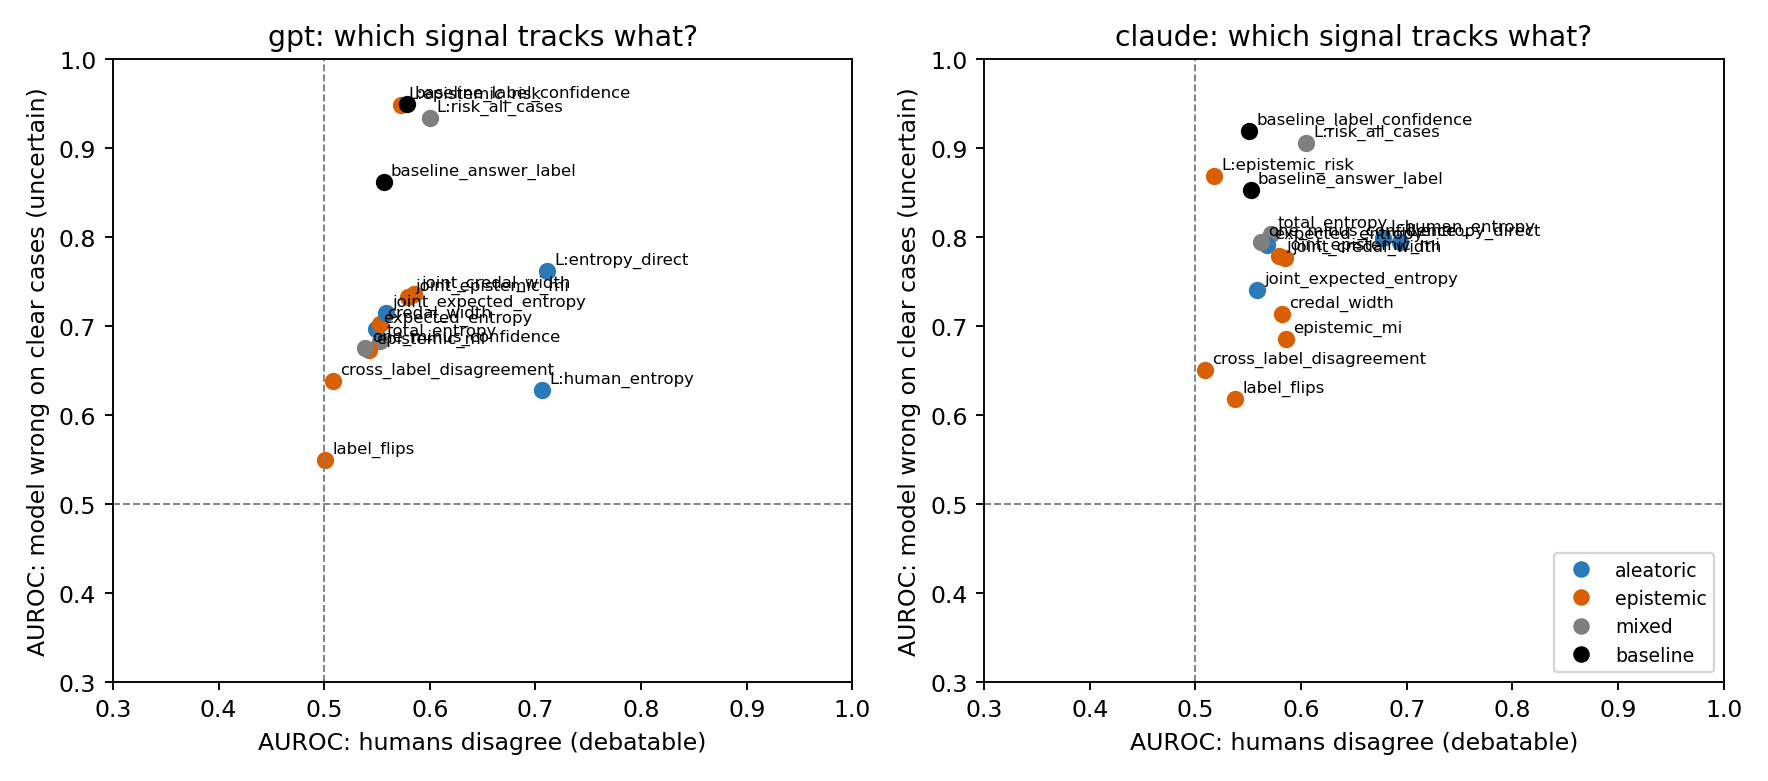

In [4]:
if READY:
    for k, res in report["per_model"].items():
        print(f"\n=== {k}")
        display(res["dissociation"].round(3))
        print("Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):")
        display(res["specialisation"].round(3))
    display(Image(filename=str(OUT / "dissociation.png")))

## 2 · Menschliche Verteilung und Fehlerrisiko

Distribution: kleinere JS-Divergenz ist besser. Fehlerrisiko: getrennt für **alle** und **klare** Fälle.
Achte auf die Anzahl Fehler auf klaren Fällen (`errors`): Bei wenigen Fehlern sind die AUROC-Werte unsicher.

In [5]:
if READY:
    for k, res in report["per_model"].items():
        print(f"\n=== {k}")
        display(res["distributions"].round(3))
        display(res["error_risk"].round(3))


=== gpt


,method,js_divergence,expected_brier,majority_agreement,human_support_of_answer,human_support_ece,entropy_spearman
0,training_prior,0.140,0.655,0.432,0.391,0.026,NaN
1,single_prompt,0.150,0.723,0.637,0.543,0.320,0.107
2,prompt_mean,0.147,0.718,0.643,0.546,0.307,0.087
3,calibrated_prompt_mean,0.076,0.562,0.643,0.546,0.039,0.256
4,tree_score_only,0.052,0.519,0.736,0.594,0.034,0.366
5,tree_no_concepts,0.049,0.517,0.717,0.589,0.018,0.431
6,tree_full,0.049,0.518,0.717,0.589,0.016,0.401


,method,subset,n,errors,error_brier,correctness_ece,error_auroc,aurc
0,raw_confidence,all,322,115,0.269,0.219,0.613,0.267
1,raw_confidence,clear_cases,123,36,0.211,0.145,0.675,0.183
2,calibrated_confidence,all,322,115,0.231,0.107,0.603,0.274
3,calibrated_confidence,clear_cases,123,36,0.205,0.111,0.663,0.190
4,answer_label_only,all,322,115,0.188,0.028,0.722,0.188
5,answer_label_only,clear_cases,123,36,0.133,0.107,0.862,0.088
6,epistemic_answer_label_only,all,322,115,0.192,0.074,0.711,0.208
7,epistemic_answer_label_only,clear_cases,123,36,0.117,0.009,0.862,0.088
8,tree_score_only,all,322,115,0.179,0.047,0.778,0.178
9,tree_score_only,clear_cases,123,36,0.115,0.083,0.897,0.081



=== claude


,method,js_divergence,expected_brier,majority_agreement,human_support_of_answer,human_support_ece,entropy_spearman
0,training_prior,0.140,0.655,0.432,0.391,0.026,NaN
1,single_prompt,0.079,0.577,0.671,0.563,0.124,0.191
2,prompt_mean,0.077,0.574,0.643,0.551,0.123,0.183
3,calibrated_prompt_mean,0.072,0.552,0.643,0.551,0.028,0.187
4,tree_score_only,0.050,0.517,0.761,0.608,0.028,0.369
5,tree_no_concepts,0.047,0.515,0.745,0.605,0.025,0.368
6,tree_full,0.047,0.515,0.745,0.605,0.025,0.368


,method,subset,n,errors,error_brier,correctness_ece,error_auroc,aurc
0,raw_confidence,all,322,115,0.193,0.068,0.758,0.191
1,raw_confidence,clear_cases,123,37,0.169,0.078,0.795,0.138
2,calibrated_confidence,all,322,115,0.189,0.056,0.753,0.198
3,calibrated_confidence,clear_cases,123,37,0.160,0.072,0.795,0.143
4,answer_label_only,all,322,115,0.204,0.024,0.679,0.219
5,answer_label_only,clear_cases,123,37,0.149,0.031,0.853,0.097
6,epistemic_answer_label_only,all,322,115,0.225,0.118,0.679,0.219
7,epistemic_answer_label_only,clear_cases,123,37,0.142,0.069,0.853,0.097
8,tree_score_only,all,322,115,0.176,0.038,0.779,0.180
9,tree_score_only,clear_cases,123,37,0.112,0.059,0.907,0.083


## 3 · Vier Reaktionen

| Situation | Reaktion |
|---|---|
| Menschen einig, Modell zuverlässig | **answer** |
| Menschen einig, Modell unsicher | **hedge** (Unsicherheit zeigen / sich enthalten) |
| Menschen uneinig, Quelle klärbar (Wortbedeutung, unklarer Bezug) | **clarify** (nachfragen) |
| Menschen uneinig, sonst | **alternatives** (Lesarten zeigen) |

Statt erfundener Kosten bekommt jedes Beispiel eine **Referenzreaktion** aus den menschlichen Stimmen und der Modellantwort.
Bewertet wird, wie gut eine Regel diese Referenz trifft (`balanced_accuracy` über answer/hedge/debatable).
`clarify` vs. `alternatives` wird nur auf Fällen mit Kategorie-Annotation (Jiang & de Marneffe) geprüft.

Verglichen werden (Schwellen jeweils nur auf Dev gewählt):

| Regel | Signale | Prüft |
|---|---|---|
| `decomposed` | Uneinigkeit + Risiko, trainiert nur auf klaren Fällen | unser Ansatz |
| `risk_trained_all_cases` | Uneinigkeit + Risiko, trainiert auf allen Fällen | Hilft das Training nur auf klaren Fällen? |
| `single_score_risk` | **ein** Score (Risiko-Baum) mit zwei Schwellen | Braucht es überhaupt zwei getrennte Signale? |
| `single_score_confidence` | **ein** Score (1 − Modellkonfidenz) | dito, ohne gelernten Bewerter |
| `raw` / `calibrated` | nur Modellwahrscheinlichkeiten | Nutzen gegenüber einfachen Methoden |
| `always_*` | keine | triviale Untergrenzen |

`clarify` vs. `alternatives`: `recall_clarify_annotated` und `recall_alternatives_annotated` zählen auf **allen** annotierten Fällen,
verpasste Fälle gelten als falsch. `conditional_...` zählt nur Fälle, bei denen das System bereits eine der beiden Reaktionen gewählt hat.

In [6]:
if READY:
    cols = ["method", "balanced_accuracy", "recall_answer", "recall_hedge", "recall_debatable",
            "answer_fraction", "hedge_fraction", "alternatives_fraction", "clarify_fraction",
            "unwarranted_answer_rate", "recall_clarify_annotated", "recall_alternatives_annotated",
            "fine_balanced_accuracy_annotated", "conditional_clarify_vs_alternatives_accuracy"]
    for k, res in report["per_model"].items():
        print(f"\n=== {k}")
        display(res["policies"][cols].round(3))
        print("Gepaarte 95%-Intervalle, Hauptkennzahl balanced_accuracy (decomposed minus Vergleich):")
        display(res["policy_intervals"])
        print("Referenz (Zeilen) vs. gewählte Reaktion (Spalten), decomposed:")
        display(res["confusion_decomposed"])


=== gpt


,method,balanced_accuracy,recall_answer,recall_hedge,recall_debatable,answer_fraction,hedge_fraction,alternatives_fraction,clarify_fraction,unwarranted_answer_rate,recall_clarify_annotated,recall_alternatives_annotated,fine_balanced_accuracy_annotated,conditional_clarify_vs_alternatives_accuracy
0,decomposed,0.627,0.825,0.719,0.338,0.491,0.304,0.140,0.065,0.405,0.053,0.20,0.126,0.353
1,risk_trained_all_cases,0.606,0.623,0.526,0.669,0.320,0.177,0.410,0.093,0.311,0.105,0.32,0.213,0.370
2,single_score_risk,0.529,0.816,0.772,0.000,0.547,0.453,0.000,0.000,0.472,0.000,0.00,0.000,NaN
3,single_score_confidence,0.415,0.667,0.579,0.000,0.599,0.401,0.000,0.000,0.606,0.000,0.00,0.000,NaN
4,raw,0.404,0.772,0.439,0.000,0.714,0.286,0.000,0.000,0.617,0.000,0.00,0.000,NaN
5,calibrated,0.425,0.395,0.000,0.881,0.224,0.000,0.627,0.149,0.375,0.263,0.60,0.432,0.488
6,always_answer,0.333,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.646,0.000,0.00,0.000,NaN
7,always_hedge,0.333,0.000,1.000,0.000,0.000,1.000,0.000,0.000,NaN,0.000,0.00,0.000,NaN
8,always_alternatives,0.333,0.000,0.000,1.000,0.000,0.000,1.000,0.000,NaN,0.000,1.00,0.500,0.568


Gepaarte 95%-Intervalle, Hauptkennzahl balanced_accuracy (decomposed minus Vergleich):


,comparison,estimate,ci_95_low,ci_95_high,valid_resamples,direction
0,balanced_accuracy_decomposed_minus_risk_traine...,0.021204,-0.026489,0.069801,500,positive favours decomposed over risk_trained_...
1,balanced_accuracy_decomposed_minus_single_scor...,0.097963,0.046816,0.152518,500,positive favours decomposed over single_score_...
2,balanced_accuracy_decomposed_minus_single_scor...,0.211998,0.152714,0.275188,500,positive favours decomposed over single_score_...
3,balanced_accuracy_decomposed_minus_calibrated,0.202025,0.138203,0.255881,500,positive favours decomposed over calibrated


Referenz (Zeilen) vs. gewählte Reaktion (Spalten), decomposed:


chosen_action,answer,hedge,alternatives,clarify
reference,,,,
alternatives,9,6,5,5
answer,94,12,4,4
clarify,8,4,6,1
debatable,38,35,25,9
hedge,9,41,5,2


... (2 outputs left out)

Gepaarte 95%-Intervalle, Hauptkennzahl balanced_accuracy (decomposed minus Vergleich):


,comparison,estimate,ci_95_low,ci_95_high,valid_resamples,direction
0,balanced_accuracy_decomposed_minus_risk_traine...,-0.029141,-0.065299,0.008855,500,positive favours decomposed over risk_trained_...
1,balanced_accuracy_decomposed_minus_single_scor...,-0.002261,-0.057899,0.053076,500,positive favours decomposed over single_score_...
2,balanced_accuracy_decomposed_minus_single_scor...,0.057418,-0.002018,0.114006,500,positive favours decomposed over single_score_...
3,balanced_accuracy_decomposed_minus_calibrated,0.057573,0.001977,0.110909,500,positive favours decomposed over calibrated


Referenz (Zeilen) vs. gewählte Reaktion (Spalten), decomposed:


chosen_action,answer,hedge,alternatives,clarify
reference,,,,
alternatives,15,5,4,1
answer,84,25,6,0
clarify,8,5,6,0
debatable,46,33,27,1
hedge,11,36,9,0


## 4 · Modellvergleich (RQ1) und Übertragbarkeit (RQ2)

Transfer: Bewerter auf GPT-Antworten gelernt, auf Claude-Antworten angewendet (und umgekehrt), ohne Nachjustieren.
Auf Dev ist das eine Entwicklungsbeobachtung. Die eigentliche Aussage kommt aus Notebook 03.

In [7]:
if READY:
    display(report["model_comparison"].round(3))
    print(report["model_comparison"].attrs)
    display(report["transfer_summary"].round(3))

,model,js_divergence,expected_brier,majority_agreement,human_support_of_answer,human_support_ece,entropy_spearman,mean_epistemic_mi,label_flip_rate,mean_credal_width
0,gpt,0.147,0.718,0.643,0.546,0.307,0.087,0.014,0.112,0.075
1,claude,0.077,0.574,0.643,0.551,0.123,0.183,0.015,0.220,0.109


{'paired_majority_agreement_difference': {'mean_difference': 0.0, 'ci_95_low': -0.057334550433591966, 'ci_95_high': 0.06256262606545637, 'groups': 272, 'bootstrap_repetitions': 500, 'direction': 'positive: gpt agrees with the majority more often than claude'}, 'same_answer_rate': 0.7111801242236024}


,assessor_from,applied_to,policy_bal_acc_transfer,policy_bal_acc_own,human_js_transfer,human_js_own,clear_error_auroc_transfer,clear_error_auroc_own
0,gpt,claude,0.466,0.544,0.066,0.047,0.728,0.869
1,claude,gpt,0.476,0.627,0.070,0.049,0.842,0.948


In [8]:
from uncertainty_project.models import tree_rules
if READY:
    for k, b in bundles.items():
        for target, rules in tree_rules(b).items():
            print(f"\n=== {k} · BAUM: {target}")
            print(rules)


=== gpt · BAUM: distribution
|--- mean_e <= 0.061
|   |--- mean_c <= 0.045
|   |   |--- mean_e <= 0.018
|   |   |   |--- mean_c <= 0.013
|   |   |   |   |--- value: [0.059, 0.680, 0.261]
|   |   |   |--- mean_c >  0.013
|   |   |   |   |--- value: [0.104, 0.498, 0.398]
|   |   |--- mean_e >  0.018
|   |   |   |--- mean_c <= 0.013
|   |   |   |   |--- value: [0.267, 0.656, 0.077]
|   |   |   |--- mean_c >  0.013
|   |   |   |   |--- value: [0.264, 0.530, 0.206]
|   |--- mean_c >  0.045
|   |   |--- mean_n <= 0.142
|   |   |   |--- value: [0.118, 0.247, 0.635]
|   |   |--- mean_n >  0.142
|   |   |   |--- epistemic_mi <= 0.019
|   |   |   |   |--- value: [0.143, 0.439, 0.418]
|   |   |   |--- epistemic_mi >  0.019
|   |   |   |   |--- value: [0.128, 0.347, 0.525]
|--- mean_e >  0.061
|   |--- mean_e <= 0.339
|   |   |--- mean_entropy <= 0.429
|   |   |   |--- mean_entropy <= 0.360
|   |   |   |   |--- value: [0.494, 0.431, 0.075]
|   |   |   |--- mean_entropy >  0.360
|   |   |   |   |-

## Unbekannte Eingaben vorbereiten (vor dem Freeze)

Christinas Punkt 3: «behaviour on unfamiliar inputs». Dafür wird eine feste Stichprobe von 300 Paaren aus **ChaosNLI-SNLI**
(Bildbeschreibungen statt MNLI-Texte, ebenfalls 100 Stimmen pro Paar) geladen. Sie wird **vor** dem Freeze gezogen und damit
zusammen mit der Methode versiegelt. Die Bewerter werden darauf **nicht** trainiert und keine Schwelle wird angepasst.
Die Stimmen bleiben in einer separaten Datei, wie beim Test.

In [9]:
from uncertainty_project.data import prepare_shift, load_split
shift_info = prepare_shift(ROOT)
print(shift_info)
print("Beispiel:", load_split(ROOT, "shift").iloc[0][["premise", "hypothesis"]].to_dict())

{'source': 'chaos_snli', 'source_rows': 1514, 'excluded_premise_overlap_with_mnli': 0, 'sample': 300, 'premise_groups': 290, 'data_digest': '99f9015ddda7d85f66a087452bc30d53974314fe27e7d589e2f41ad44bd509c1'}
Beispiel: {'premise': 'A boy in s striped shirt is jumping in front of a water fountain.', 'hypothesis': 'A boy jumps in a crowded area by a fountain.'}


## Methode vor dem Test festhalten

Wenn alles steht: `FREEZE_METHOD = True`. Config, Code, Daten (inkl. der Stichprobe unbekannter Eingaben), Trainingsantworten und Bewerter beider Modelle
werden mit Prüfsummen protokolliert. Notebook 03 verweigert den Test, wenn danach etwas verändert wurde.

In [11]:
FREEZE_METHOD = True
if READY and FREEZE_METHOD:
    frozen = freeze_experiment(ROOT)
    print("Methode festgehalten:", frozen["protocol_id"][:16])
else:
    print("Noch nicht eingefroren.")

Methode festgehalten: 3942fc496262a9b3
